In [1]:
import pandas as pd
import torch

from pathlib import Path
from sentence_transformers import SentenceTransformer

# Localizar dataset
carpeta = Path("data")

if not carpeta.exists():
    carpeta = Path("../data")

df = pd.read_csv(
    carpeta / "SGSST_auditorias_sinteticas_5000.csv"
)

# Separar datos
train = df[df["split"] == "train"].copy()
val = df[df["split"] == "val"].copy()
test = df[df["split"] == "test"].copy()

print("Entrenamiento:", len(train))
print("Validación:", len(val))
print("Prueba:", len(test))

# Seleccionar GPU
device = "cuda" if torch.cuda.is_available() else "cpu"

# Cargar MiniLM
modelo = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    device=device
)

print("\nModelo cargado en:", modelo.device)

d:\VIVIAN\Uis\Quinto semestre\Deep Learning\Proyecto Mini-Transforms\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Entrenamiento: 3752
Validación: 624
Prueba: 624


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1931.76it/s]



Modelo cargado en: cuda:0


In [3]:
# Embeddings de los registros históricos
emb_train = modelo.encode(
    train["hallazgo"].tolist(),
    convert_to_tensor=True,
    normalize_embeddings=True,
    batch_size=32,
    show_progress_bar=True
)

# Embeddings de validación
emb_val = modelo.encode(
    val["hallazgo"].tolist(),
    convert_to_tensor=True,
    normalize_embeddings=True,
    batch_size=32,
    show_progress_bar=True
)

print("Embeddings entrenamiento:", emb_train.shape)
print("Embeddings validación:", emb_val.shape)

Batches: 100%|██████████| 20/20 [00:00<00:00, 53.99it/s]

Embeddings entrenamiento: torch.Size([3752, 384])
Embeddings validación: torch.Size([624, 384])


In [4]:
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, f1_score

# Similitud entre validación y entrenamiento
similitudes = emb_val @ emb_train.T

# Antecedente más parecido
indices = torch.argmax(similitudes, dim=1).cpu().numpy()

# Obtener categorías predichas
predicciones = train.iloc[indices]["categoria"].to_numpy()

# Categorías verdaderas
reales = val["categoria"].to_numpy()

# Métricas
accuracy = accuracy_score(reales, predicciones)
macro_f1 = f1_score(
    reales,
    predicciones,
    average="macro",
    zero_division=0
)

print("RESULTADOS DE MINILM PREENTRENADO")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")

RESULTADOS DE MINILM PREENTRENADO
Accuracy: 0.3365
Macro-F1: 0.2724


REPORTE POR CATEGORÍA

                                                    precision    recall  f1-score   support

                             Condiciones locativas      0.000     0.000     0.000        52
                         Control documental SG-SST      0.641     0.962     0.769        52
                  Elementos de proteccion personal      0.805     0.635     0.710        52
                      Formacion y competencias SST      0.000     0.000     0.000        52
                       Gestion SST de contratistas      0.231     0.058     0.092        52
                    Gestion de sustancias quimicas      0.000     0.000     0.000        52
Identificacion de peligros y valoracion de riesgos      0.046     0.096     0.062        52
                      Inspecciones y mantenimiento      0.000     0.000     0.000        52
          Investigacion de incidentes y accidentes      0.703     0.865     0.776        52
             Preparacion y respuesta a emergencias      

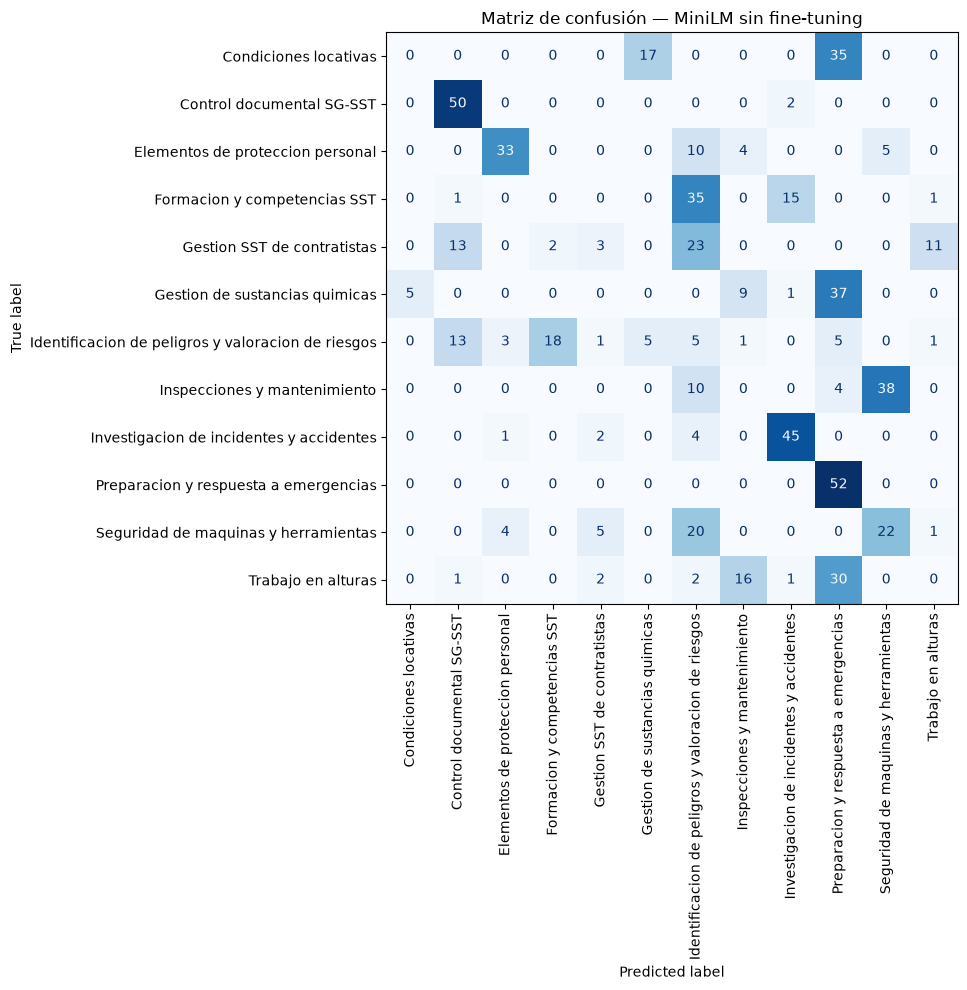

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Obtener las categorías
categorias = sorted(df["categoria"].unique())

# Reporte de clasificación
print("REPORTE POR CATEGORÍA\n")

print(
    classification_report(
        reales,
        predicciones,
        labels=categorias,
        zero_division=0,
        digits=3
    )
)

# Matriz de confusión
matriz = confusion_matrix(
    reales,
    predicciones,
    labels=categorias
)

fig, ax = plt.subplots(figsize=(13, 10))

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=categorias
)

visualizacion.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=False
)

plt.title("Matriz de confusión — MiniLM sin fine-tuning")
plt.tight_layout()
plt.show()